# CAC 40 Portfolio Backtest

**Anna Docheva and Julien Kanaan**

Course project in numerical processing of financial data at École Polytechnique.

In [1]:
import numpy as np
import pandas as pd
import math
import matplotlib.pyplot as plt


# Dataset

You will use the dataset (Excel files) of one-minute observations (OHLC prices) provided in Moodle for TP1 (Session 1). The dataset consists in the 40 constituents of the French stock index CAC 40 (as of 2022/2023). The biggest capitalizations are: LVMH (MC), L'Oréal (OR), TotalEnergies (TTE), Sanofi (SAN), Hermès (RMS), Airbus (AIR)...

You have first to restrict arbitrarily your investment universe to ten of these stocks and work with this universe for all the project.

The time range is September 2022-March 2023. Pay attention to the fact that some stocks don't have a price every minute (less liquid, like SW): avoid them.



In [2]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path("./dataset TP1")
stocks = ["MC", "OR", "TTE", "SAN", "RMS", "AIR", "CS", "DG", "ENGI", "BNP"]

def read_close(company):
    path = DATA_DIR / f"{company}_Prices.xlsx"
    x = pd.read_excel(path, header=1, index_col=0)  
    x.index = pd.to_datetime(x.index, dayfirst=True, errors="coerce")

    # we keep only close prices
    close = x[["Close"]].copy()
    close.columns = [f"{company} close"]
    return close

# Outer-join all series on their existing timestamps
df = pd.concat([read_close(c) for c in stocks], axis=1, join="outer").sort_index()

# We keep only timestamps where ALL stocks have a price
df = df.dropna(how="any")

df.head()

# Creating a porfolio (Part 1)

* **1.a/** Split your dataset of prices in separate business days, from day 1 to day $n$. Calculate and put in a dataframe the price returns of the 10 stocks at a daily time scale.



In [3]:
# Build daily close prices
daily_close_df = df.groupby(df.index.date).last().copy()
daily_close_df.index = pd.to_datetime(daily_close_df.index)

# Compute daily returns
returns_df = daily_close_df.pct_change()
returns_df = returns_df.dropna()

# rename columns appropriately
returns_df = returns_df.rename(columns={col: col.replace(" close", " return") for col in returns_df.columns})


display(daily_close_df.head())
display(returns_df.head())
print('Daily close shape:', daily_close_df.shape)
print('Daily returns shape:', returns_df.shape)

Daily close shape: (136, 10)
Daily returns shape: (135, 10)


* **1.b/** Calculate both the correlation matrix and the covariance matrix $\Sigma$ of the daily price returns of the 10 stocks.

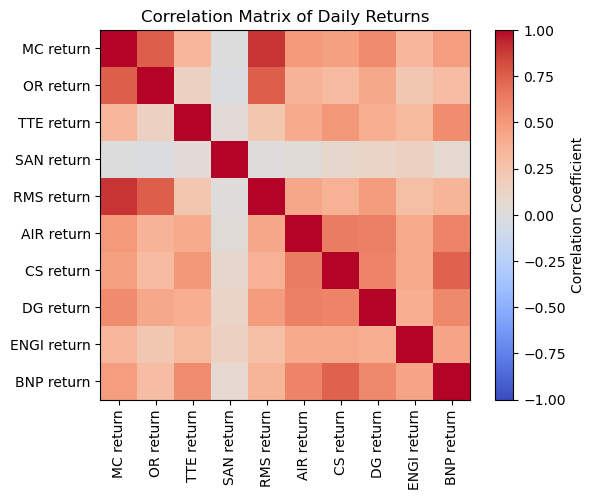

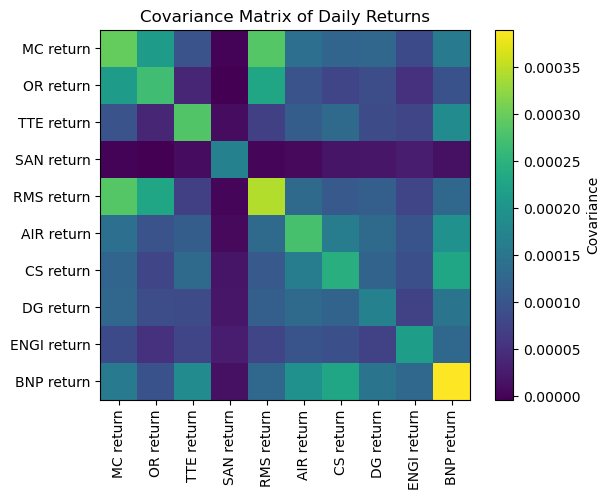

In [4]:
corr_matrix = returns_df.corr()
plt.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='Correlation Coefficient')
plt.title('Correlation Matrix of Daily Returns')
plt.xticks(ticks=np.arange(len(returns_df.columns)), labels=returns_df.columns, rotation=90)
plt.yticks(ticks=np.arange(len(returns_df.columns)), labels=returns_df.columns)
plt.xticks(rotation=90)
plt.show()

cov_matrix = returns_df.cov()
plt.imshow(cov_matrix, cmap='viridis')
plt.colorbar(label='Covariance')
plt.title('Covariance Matrix of Daily Returns')
plt.xticks(ticks=np.arange(len(returns_df.columns)), labels=returns_df.columns, rotation=90)
plt.yticks(ticks=np.arange(len(returns_df.columns)), labels=returns_df.columns)
plt.show()

* **1.c/** For each stock, calculate the autocorrelation of the daily time series of returns, for a lag of one day.

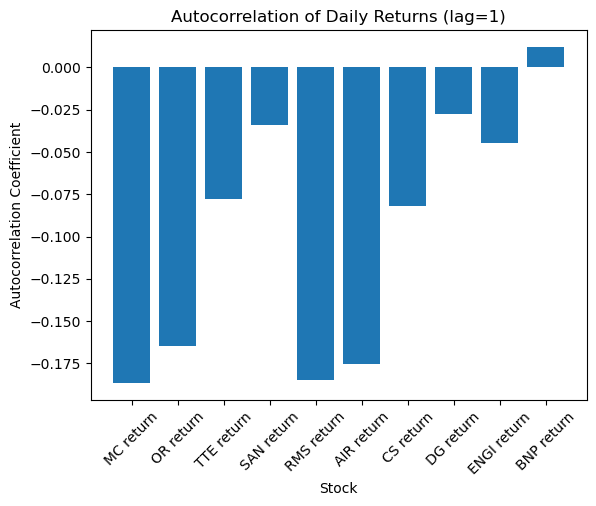

In [5]:
autocorr_matrix = returns_df.apply(lambda x: x.autocorr(lag=1))
plt.bar(returns_df.columns, autocorr_matrix)
plt.title('Autocorrelation of Daily Returns (lag=1)')
plt.xlabel('Stock')
plt.ylabel('Autocorrelation Coefficient')
plt.xticks(rotation=45)
plt.show()

* **1.d/** Using only the autocorrelations calculated above and the observation of the price returns at day $i$ (for $1\leq i\leq n-1$), propose a projection $R_{i+1,j}$ of the future price return at day $i+1$ for each stock $j$ ($1\leq j\leq 10$). Justify briefly the relevance of the method.



In [6]:
rho_vec = np.array(autocorr_matrix)

projected_returns_df = pd.DataFrame(
    returns_df.iloc[:-1].to_numpy() * rho_vec,   # r̂_{i+1,j} = rho_j * r_{i,j}
    index=returns_df.index[1:],                  # prediction for day i+1
    columns=returns_df.columns
)

projected_returns_df.index.name = "date"
projected_returns_df.head()

#### Justification

We use a simple stock-by-stock AR(1) assumption for daily returns:

$$R_{t+1,j} = \rho_j R_{t,j} + \varepsilon_{t+1,j},$$

where $\rho_j$ is the lag-1 autocorrelation estimated from the historical daily returns of stock $j$.

Under this model, the conditional expectation is:

$$\mathbb{E}[R_{t+1,j} \mid R_{t,j}] = \rho_j R_{t,j},$$

so the projection

$$\hat{R}_{t+1,j} = \rho_j R_{t,j}$$

is a natural one-step-ahead predictor using only the lag-1 autocorrelation and return at day $t$.

* **1.e/** Using the above projection as a proxy for the expected return, calculate the Markowitz portfolio such that the sum of weights is equal to 1, that is the optimal vector of weights for day $i+1$ is
$$\Omega_{i+1}=\frac{1}{\mathbf{1}'_{10}\Sigma^{-1}R_{i+1}}\Sigma^{-1}R_{i+1},$$
where $R_{i+1}=(R_{i+1,1},...,R_{i+1,10})'$ and $\mathbf{1}_{10}$ is a vector of ones of size 10.



In [7]:
# Covariance matrix Sigma from daily returns (1.b)
Sigma_inv = pd.DataFrame(np.linalg.inv(cov_matrix.values), index=cov_matrix.index, columns=cov_matrix.columns)

one_vec = np.ones(len(cov_matrix.columns))

weights_records = []
for i in range(len(projected_returns_df)):
    r_next = projected_returns_df.iloc[i].values.astype(float)
    numer = Sigma_inv.values @ r_next
    denom = one_vec @ numer
    w = numer / denom

    weights_records.append(w)

weights_df = pd.DataFrame(weights_records, index=projected_returns_df.index, columns=returns_df.columns)
weights_df.index.name = 'date'

# fix column names
weights_df = weights_df.rename(columns={c: c.replace(' return', ' weight') for c in weights_df.columns})

display(weights_df.head())

weights_sum_check = weights_df.sum(axis=1)
print('Weights dataframe shape:', weights_df.shape)
print('Average sum of weights:', weights_sum_check.mean())


,MC weight,OR weight,TTE weight,SAN weight,RMS weight,AIR weight,CS weight,DG weight,ENGI weight,BNP weight
date,,,,,,,,,,
2022-09-21,9.288658,-2.091872,-0.038393,0.575012,-6.134551,3.378723,-0.578359,-1.588188,0.480343,-2.291373
2022-09-22,0.555642,-2.761321,-0.158490,-0.054852,6.455084,5.716274,-2.143267,-5.954775,0.215129,-0.869426
2022-09-23,-2.139057,-0.647749,-0.033563,0.101714,4.782029,0.309998,0.310680,-1.064244,-0.281198,-0.338610
2022-09-26,4.436123,-2.338150,1.161898,0.062632,-0.174094,-0.623931,1.200337,-0.696104,-0.139335,-1.889377
2022-09-27,-3.163807,-2.230098,-1.642843,0.196761,2.870556,0.625101,4.360037,-0.158578,2.027762,-1.884891


Weights dataframe shape: (134, 10)
Average sum of weights: 1.0


* **1.f/** Add in your dataframe the time series of realized price returns for your portfolio, between day 2 and day $n$, using the dynamic weights calculated above.



In [8]:
# make column names match
w = weights_df.copy()
w.columns = w.columns.str.replace(" weight", " return")

# align rows by date (we need to drop the extra day in returns_df)
w_aligned, r_aligned = w.align(returns_df, join="inner", axis=0)

# realized portfolio returns: r_p,t = sum_j w_{t,j} * r_{t,j}
portfolio_realized_returns = (w_aligned * r_aligned).sum(axis=1)

# build the output dataframe 
portfolio_returns_df = portfolio_realized_returns.rename("portfolio_realized_return").to_frame()
portfolio_returns_df.index.name = "date"

display(portfolio_returns_df.head())
print("Portfolio returns shape:", portfolio_returns_df.shape)
print("Date range:", portfolio_returns_df.index.min().date(), "to", portfolio_returns_df.index.max().date())

Portfolio returns shape: (134, 1)
Date range: 2022-09-21 to 2023-03-28


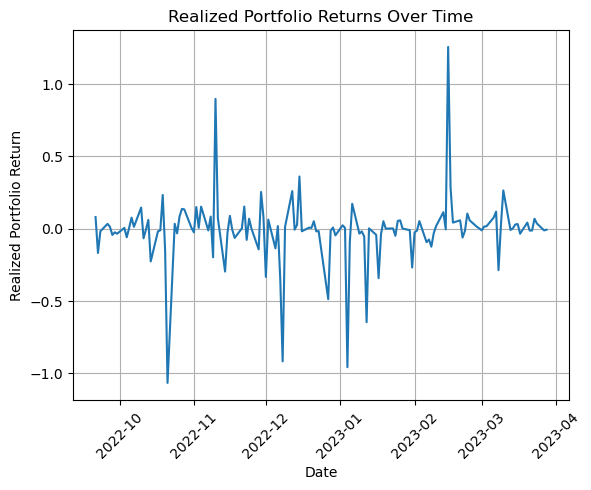

In [9]:
# Plot the realized portfolio returns over time

plt.plot(portfolio_returns_df.index, portfolio_returns_df["portfolio_realized_return"])
plt.title("Realized Portfolio Returns Over Time")
plt.xlabel("Date")
plt.ylabel("Realized Portfolio Return")
plt.xticks(rotation=45)
plt.grid()
plt.show()

* **1.g/** What is the main methodological bias we had in the construction of this portfolio that would affect the quality of a backtest?

#### Methodological bias

The main methodological bias in our portfolio construction is **look-ahead bias**, which comes from estimating the covariance matrix and the autocorrelations using the **entire dataset**.

In our methodology, we compute the **autocorrelations** and the **covariance matrix** $\Sigma$ using the **full sample of returns**. We then use them to compute the **portfolio weights** and construct the portfolio. However, when estimating these parameters, we actually use **future information** (returns that occur after the portfolio allocation date).

This creates a **look-ahead bias**, because in reality we would only have access to past data.

#### Consequence:
Because the parameters are estimated using future data, the portfolio strategy may appear to be  performing better than it would be in practice.

# Risk and performance evaluation (Part 2)

* **2.a/** Determine the ex-ante (that is using $R_{i+1,j}$ as the return) and ex-post (that is the real return observed after each trading day) Sharpe ratio of your portfolio (consider 0 as the risk-free rate).

In [10]:
# Ex-ante portfolio return: use projected returns and the weights
# For each day i+1, the expected portfolio return is w_{i+1}' @ R_{i+1}
# where R_{i+1} are the projected (AR(1)) returns.

# Align weights and projected returns on the same dates
w_ante = weights_df.copy()
w_ante.columns = w_ante.columns.str.replace(' weight', ' return')
w_ante_aligned, proj_aligned = w_ante.align(projected_returns_df, join='inner', axis=0)

# ex-ante portfolio return for each day
portfolio_exante = (w_ante_aligned * proj_aligned).sum(axis=1)

# Sharpe = mean / std  (risk-free = 0)
sharpe_exante = portfolio_exante.mean() / portfolio_exante.std()

# Ex-post Sharpe: use the realized returns we already computed in 1.f
realized = portfolio_returns_df['portfolio_realized_return']
sharpe_expost = realized.mean() / realized.std()

print(f'Ex-ante Sharpe ratio : {sharpe_exante:.4f}')
print(f'Ex-post Sharpe ratio : {sharpe_expost:.4f}')


Ex-ante Sharpe ratio : -0.1809
Ex-post Sharpe ratio : -0.0500


#### Interpretation

The **ex-ante Sharpe ratio** measures the expected risk-adjusted performance based on our AR(1) projected returns and the Markowitz weights. It reflects how good the strategy *should* perform according to the model.

The **ex-post Sharpe ratio** measures the actual realized risk-adjusted performance of the portfolio. It tells us how the portfolio *actually* performed.

A gap between the two indicates that the model's predictions deviate from reality, which is expected given the simplicity of the AR(1) projection and the look-ahead bias discussed earlier.


* **2.b/** Calculate the ex-post upside potential ratio of your portfolio.

In [11]:
# The upside potential ratio is defined as:
#   UPR = E[max(R_p - tau, 0)] / sqrt( E[min(R_p - tau, 0)^2] )
# with tau = 0 (the risk-free rate / minimum acceptable return).

tau = 0  # threshold = risk-free rate

r_p = realized.values  # realized portfolio returns

# Upside potential: average of positive excess returns
upside = np.mean(np.maximum(r_p - tau, 0))

# Downside deviation: sqrt of mean squared negative excess returns
downside_dev = np.sqrt(np.mean(np.minimum(r_p - tau, 0) ** 2))

upr = upside / downside_dev

print(f'Upside potential     : {upside:.6f}')
print(f'Downside deviation   : {downside_dev:.6f}')
print(f'Upside potential ratio: {upr:.4f}')


Upside potential     : 0.051767
Downside deviation   : 0.181386
Upside potential ratio: 0.2854


#### Interpretation

The **upside potential ratio (UPR)** is an alternative to the Sharpe ratio that distinguishes between upside and downside risk. Unlike the Sharpe ratio which penalizes all volatility equally, the UPR only penalizes *downside* deviations below the threshold $\tau = 0$.

- A UPR > 1 indicates that the upside potential exceeds the downside risk.
- A UPR < 1 indicates that the downside risk dominates the upside.


* **2.c/** Calculate the maximum drawdown of your portfolio.

Maximum drawdown: -1.1456 (-114.56%)


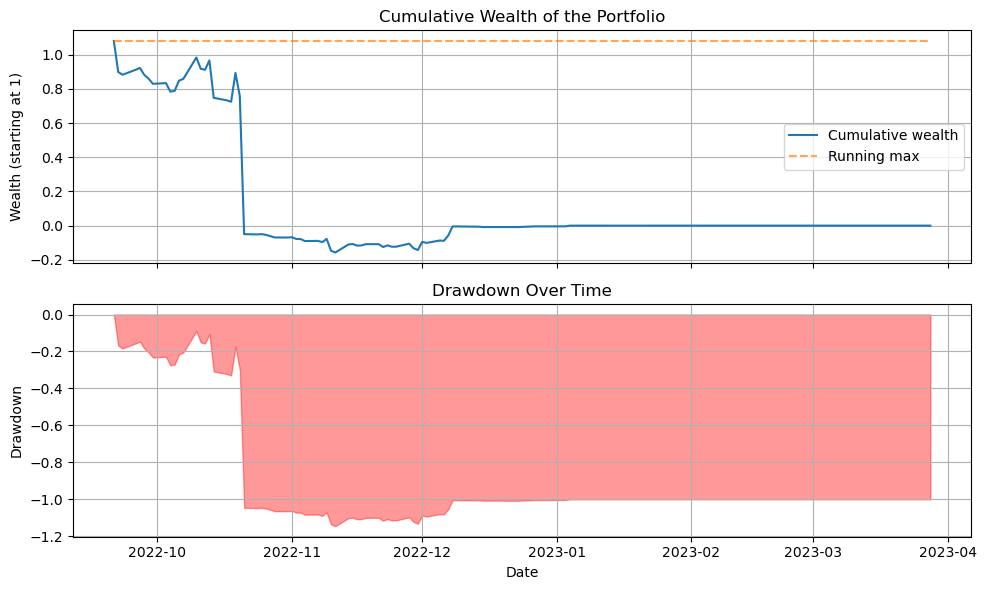

In [12]:
# Build the cumulative wealth curve (starting from 1)
cumulative_wealth = (1 + realized).cumprod()

# Running maximum of the wealth curve
running_max = cumulative_wealth.cummax()

# Drawdown at each point: how far below the running max
drawdown = (cumulative_wealth - running_max) / running_max

max_drawdown = drawdown.min()  # most negative value

print(f'Maximum drawdown: {max_drawdown:.4f} ({max_drawdown*100:.2f}%)')

# Plot the wealth curve and drawdowns
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

axes[0].plot(cumulative_wealth.index, cumulative_wealth.values, label='Cumulative wealth')
axes[0].plot(running_max.index, running_max.values, '--', label='Running max', alpha=0.7)
axes[0].set_title('Cumulative Wealth of the Portfolio')
axes[0].set_ylabel('Wealth (starting at 1)')
axes[0].legend()
axes[0].grid(True)

axes[1].fill_between(drawdown.index, drawdown.values, 0, color='red', alpha=0.4)
axes[1].set_title('Drawdown Over Time')
axes[1].set_ylabel('Drawdown')
axes[1].set_xlabel('Date')
axes[1].grid(True)

plt.tight_layout()
plt.show()


#### Interpretation

The **maximum drawdown** is the largest peak-to-trough decline in the cumulative portfolio value. It measures the worst loss an investor could have experienced during the backtest period.

This is a key risk metric because, unlike volatility, it captures the magnitude of actual losses that an investor would have faced.

A drawdown exceeding $100\%$ is possible here because the unconstrained Markowitz weights imply leveraged positions: the portfolio can borrow implicitly, so cumulative losses are not capped at the initial capital.

* **2.d/** Using the formula presented in the course, calculate the additive contribution of each of the 10 stocks to the volatility of the portfolio.

Portfolio volatility (avg weights): 0.016219
Sum of risk contributions         : 0.016219



,Avg weight,Risk contribution,% of total vol
Stock,,,
MC,-0.921199,-0.003461,-21.340071
OR,0.810271,0.006856,42.270959
TTE,0.606837,0.003776,23.280189
SAN,0.095375,0.000096,0.594713
RMS,0.490354,0.003432,21.157721
AIR,0.486103,0.002965,18.279057
CS,0.260445,0.000775,4.779879
DG,-0.456490,-0.000262,-1.617350
ENGI,0.273837,0.001149,7.081465


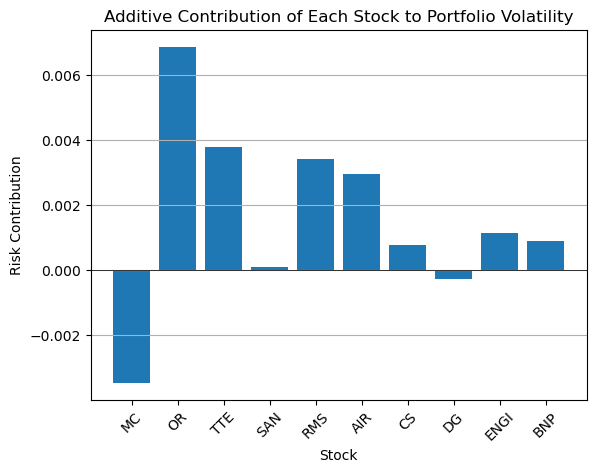

In [13]:
# From the course, the additive volatility contribution of stock j is:
#   RC_j = w_j * (Sigma @ w)_j / sigma_p
# where sigma_p = sqrt(w' @ Sigma @ w)
# and sum(RC_j) = sigma_p (the total portfolio volatility).
#
# Since weights change every day, we compute the average weights
# over the entire period and use the full-sample covariance matrix.

# Average weight vector
w_avg = weights_df.mean().values

# Covariance matrix (use the one computed in 1.b, aligned with stock order)
Sigma = cov_matrix.values

# Portfolio volatility under average weights
sigma_p = np.sqrt(w_avg @ Sigma @ w_avg)

# Marginal contribution: (Sigma @ w) / sigma_p
marginal_contrib = (Sigma @ w_avg) / sigma_p

# Additive (risk) contribution: RC_j = w_j * marginal_contrib_j
risk_contrib = w_avg * marginal_contrib

# Verification: sum of contributions should equal sigma_p
print(f'Portfolio volatility (avg weights): {sigma_p:.6f}')
print(f'Sum of risk contributions         : {risk_contrib.sum():.6f}')
print()

# Display as a nice dataframe
contrib_df = pd.DataFrame({
    'Stock': stocks,
    'Avg weight': w_avg,
    'Risk contribution': risk_contrib,
    '% of total vol': risk_contrib / sigma_p * 100
}).set_index('Stock')

display(contrib_df)

# Bar chart
plt.bar(stocks, risk_contrib)
plt.title('Additive Contribution of Each Stock to Portfolio Volatility')
plt.xlabel('Stock')
plt.ylabel('Risk Contribution')
plt.axhline(y=0, color='black', linewidth=0.5)
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()


#### Interpretation

The additive decomposition breaks down the total portfolio volatility $\sigma_p$ into contributions from each stock:

$$\sigma_p = \sum_{j=1}^{10} RC_j = \sum_{j=1}^{10} \omega_j \cdot \frac{(\Sigma \omega)_j}{\sigma_p}$$

Each $RC_j$ tells us how much stock $j$ adds (or reduces) the total portfolio risk, accounting for both its weight and its covariance with the other stocks.

- A **positive** contribution means the stock adds to overall portfolio risk.
- A **negative** contribution means the stock has a diversifying effect (reduces risk).

This decomposition is useful to identify which stocks are the main drivers of portfolio risk.
